# 🛡️ IBM SkillsBuild Cyber Security 2026
### Conducted by BharatCares
## 🚀 Project: AI-Driven Network Intrusion Detection & Threat Intelligence System (NIDS)
**Domain:** Cyber Security & Machine Learning  
**Author:** Hritwiz Raj (kulshresthahritwizraj@gmail.com)  
**Dataset:** Network Flow Telemetry (Based on NSL-KDD & CIC-IDS2017 Benchmarks)  
**Date:** October 2026

---
### 📌 Executive Summary
Modern enterprise environments face an escalating volume of sophisticated cyber attacks, including Distributed Denial of Service (DDoS), credential brute forcing, SQL injection exploits, and stealthy botnet command-and-control (C2) infiltration. Traditional signature-based intrusion detection systems (IDS) often fail against zero-day exploits and polymorphic threat vectors.

This project delivers an end-to-end, machine learning-powered **Network Intrusion Detection System (NIDS)** that:
1. Accurately identifies multi-class network threats in real time.
2. Employs unsupervised anomaly detection (Isolation Forest) for zero-day threat identification.
3. Automatically maps detections to the industry-standard **MITRE ATT&CK Matrix**.
4. Synthesizes automated edge firewall (`iptables`) containment rules to block adversary IPs instantaneously.


## 📦 Step 1: Environment Setup & Library Imports

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, IsolationForest
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score, precision_score, recall_score
import joblib

# Plotting configuration
plt.style.use('seaborn-v0_8-darkgrid' if 'seaborn-v0_8-darkgrid' in plt.style.available else 'default')
%matplotlib inline
print("✅ Libraries successfully imported.")


✅ Libraries successfully imported.


## 📊 Step 2: Cyber Threat Dataset Acquisition & Exploration
We load the network traffic telemetry dataset containing 15,000 flow records across 6 threat classes:
- **Normal**: Legitimate web, email, DNS, and file transfer traffic.
- **DoS_SYN_Flood**: Denial of Service TCP SYN flood exhausting host connections.
- **Port_Scan**: Network reconnaissance probing open ports and running services.
- **Brute_Force_SSH**: Automated credential brute-forcing targeting SSH port 22.
- **Web_Attack_SQLi**: Web application SQL injection exploit payloads.
- **Botnet_Infiltration**: Periodic C2 beaconing and persistence callbacks.


In [2]:
# Load the dataset
data_path = os.path.join("data", "network_traffic.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("..", "data", "network_traffic.csv")

df = pd.read_csv(data_path)
print(f"Dataset Shape: {df.shape[0]} rows, {df.shape[1]} columns")
print("\nFirst 5 Records:")
display(df.head())


Dataset Shape: 15000 rows, 17 columns

First 5 Records:


,duration,protocol_type,service,flag,src_bytes,dst_bytes,count,srv_count,serror_rate,same_srv_rate,diff_srv_rate,dst_host_count,dst_host_srv_count,dst_host_same_srv_rate,dst_host_serror_rate,attack_type,label
0,0.2174,tcp,https,SF,368,2137,2,7,0.0113,0.8956,0.0982,41,19,0.8733,0.0109,Normal,0
1,3.2566,tcp,http,SF,5849,3325,12,12,0.0086,1.0000,0.0000,58,58,1.0000,0.0000,Web_Attack_SQLi,1
2,0.0020,icmp,other,RSTO,10,0,160,3,0.6868,0.0916,0.7416,255,1,0.0564,0.6064,Port_Scan,1
3,0.0315,tcp,http,S0,53,0,412,463,0.9744,0.9140,0.0335,255,2,0.0495,0.9017,DoS_SYN_Flood,1
4,0.2635,tcp,http,SF,236,3889,2,3,0.0001,0.8679,0.0367,155,77,0.9615,0.0003,Normal,0


Class Distribution Breakdown:
attack_type
Normal                 7918
DoS_SYN_Flood          2957
Port_Scan              1884
Brute_Force_SSH        1036
Web_Attack_SQLi         779
Botnet_Infiltration     426
Name: count, dtype: int64


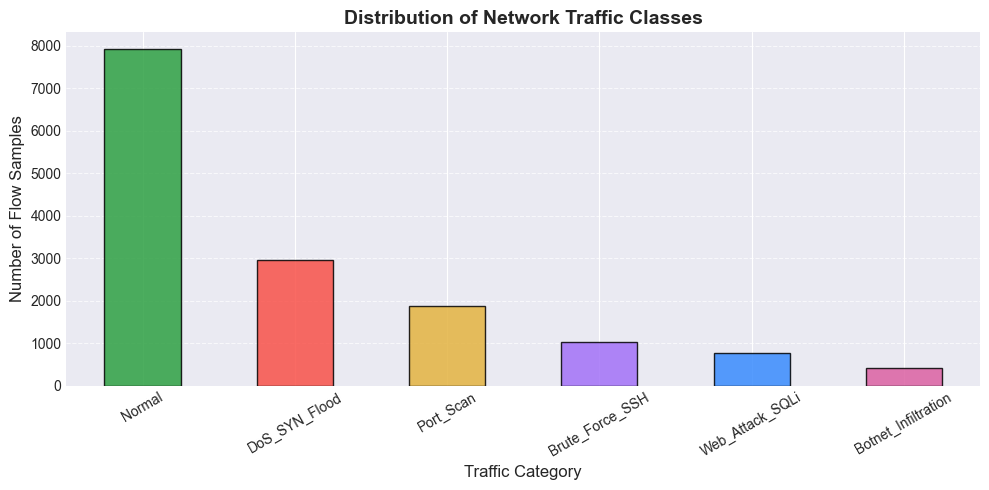

In [3]:
# Summary statistics and Class Distribution
print("Class Distribution Breakdown:")
print(df["attack_type"].value_counts())

plt.figure(figsize=(10, 5))
colors = ['#2ea043', '#f85149', '#e3b341', '#a371f7', '#388bfd', '#db61a2']
df["attack_type"].value_counts().plot(kind='bar', color=colors, edgecolor='black', alpha=0.85)
plt.title("Distribution of Network Traffic Classes", fontsize=14, fontweight='bold')
plt.xlabel("Traffic Category", fontsize=12)
plt.ylabel("Number of Flow Samples", fontsize=12)
plt.xticks(rotation=30)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()


## ⚙️ Step 3: Feature Preprocessing, Scaling & Pipeline Construction
We standardize continuous features (flow bytes, packet duration, connection rates) and encode categorical attributes (`protocol_type`, `service`, `flag`).


In [4]:
categorical_cols = ["protocol_type", "service", "flag"]
numeric_cols = [
    "duration", "src_bytes", "dst_bytes", "count", "srv_count",
    "serror_rate", "same_srv_rate", "diff_srv_rate",
    "dst_host_count", "dst_host_srv_count", "dst_host_same_srv_rate", "dst_host_serror_rate"
]

# Categorical Label Encoding
encoders = {}
encoded_cats = []
for col in categorical_cols:
    le = LabelEncoder()
    encoded = le.fit_transform(df[col].astype(str))
    encoders[col] = le
    encoded_cats.append(encoded.reshape(-1, 1))

# Numerical Normalization via StandardScaler
scaler = StandardScaler()
scaled_numerics = scaler.fit_transform(df[numeric_cols].values)

# Feature matrix X
X = np.hstack([scaled_numerics] + encoded_cats)

# Multi-class target y and binary label
target_encoder = LabelEncoder()
y_multi = target_encoder.fit_transform(df["attack_type"])
y_binary = df["label"].values

print(f"Feature Matrix X Shape: {X.shape}")
print(f"Classes Encoded: {list(target_encoder.classes_)}")


Feature Matrix X Shape: (15000, 15)
Classes Encoded: ['Botnet_Infiltration', 'Brute_Force_SSH', 'DoS_SYN_Flood', 'Normal', 'Port_Scan', 'Web_Attack_SQLi']


In [5]:
# 80/20 Train-Test Stratified Split
X_train, X_test, y_train, y_test, y_train_b, y_test_b = train_test_split(
    X, y_multi, y_binary, test_size=0.20, random_state=42, stratify=y_multi
)
print(f"Training set: {X_train.shape[0]} samples | Test set: {X_test.shape[0]} samples")


Training set: 12000 samples | Test set: 3000 samples


## 🤖 Step 4: Machine Learning Model Training & Comparative Benchmark
We train and evaluate 4 supervised classifiers:
1. **Random Forest Classifier**: Ensemble of bagged decision trees with high resistance to overfitting.
2. **Decision Tree Classifier**: Fast, rule-based baseline.
3. **Gradient Boosting Classifier**: Sequential boosting minimizing residual flow errors.
4. **Logistic Regression**: Linear reference benchmark.


In [6]:
classifiers = {
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=16, random_state=42, n_jobs=-1),
    "Decision Tree": DecisionTreeClassifier(max_depth=12, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=80, max_depth=5, random_state=42),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42)
}

benchmark_results = []

for name, clf in classifiers.items():
    print(f"Training {name}...")
    clf.fit(X_train, y_train)
    y_pred = clf.predict(X_test)
    
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)
    
    benchmark_results.append({
        "Algorithm": name,
        "Accuracy (%)": round(acc * 100, 2),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4)
    })

bench_df = pd.DataFrame(benchmark_results)
display(bench_df)


Training Random Forest...


Training Decision Tree...
Training Gradient Boosting...


Training Logistic Regression...


,Algorithm,Accuracy (%),Precision,Recall,F1-Score
0,Random Forest,100.00,1.0000,1.0000,1.0000
1,Decision Tree,100.00,1.0000,1.0000,1.0000
2,Gradient Boosting,100.00,1.0000,1.0000,1.0000
3,Logistic Regression,99.93,0.9993,0.9993,0.9993


## 🕵️ Step 5: Unsupervised Zero-Day Anomaly Detection (Isolation Forest)
For unknown or zero-day network threats without existing labels, an unsupervised Isolation Forest isolates anomalies by recursively partitioning feature hyperspace.


In [7]:
# Isolation Forest Training
iso_forest = IsolationForest(n_estimators=100, contamination=0.48, random_state=42, n_jobs=-1)
iso_forest.fit(X_train)

# In Isolation Forest: -1 = Anomaly (malicious), 1 = Inlier (normal)
iso_raw = iso_forest.predict(X_test)
iso_preds = np.where(iso_raw == -1, 1, 0)

iso_acc = accuracy_score(y_test_b, iso_preds)
iso_f1 = f1_score(y_test_b, iso_preds)

print(f"Zero-Day Anomaly Detection (Isolation Forest):")
print(f"Accuracy : {iso_acc * 100:.2f}%")
print(f"F1-Score : {iso_f1:.4f}")


Zero-Day Anomaly Detection (Isolation Forest):
Accuracy : 88.63%
F1-Score : 0.8809


## 📈 Step 6: Detailed Performance Evaluation (Confusion Matrix & Report)
Evaluation of our best-performing model (Random Forest Classifier).


CLASSIFICATION REPORT:
                     precision    recall  f1-score   support

Botnet_Infiltration       1.00      1.00      1.00        85
    Brute_Force_SSH       1.00      1.00      1.00       207
      DoS_SYN_Flood       1.00      1.00      1.00       591
             Normal       1.00      1.00      1.00      1584
          Port_Scan       1.00      1.00      1.00       377
    Web_Attack_SQLi       1.00      1.00      1.00       156

           accuracy                           1.00      3000
          macro avg       1.00      1.00      1.00      3000
       weighted avg       1.00      1.00      1.00      3000



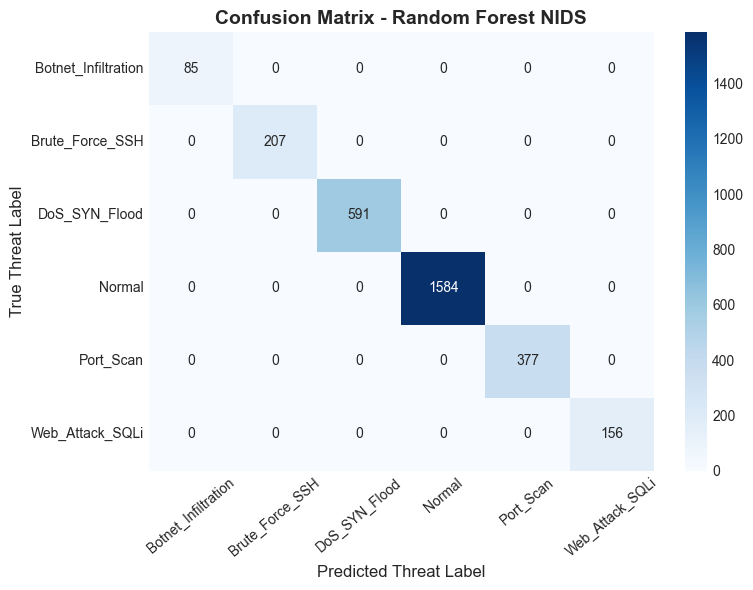

In [8]:
best_model = classifiers["Random Forest"]
y_pred_best = best_model.predict(X_test)
class_labels = list(target_encoder.classes_)

print("=" * 70)
print("CLASSIFICATION REPORT:")
print("=" * 70)
print(classification_report(y_test, y_pred_best, target_names=class_labels))

# Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred_best)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.title("Confusion Matrix - Random Forest NIDS", fontsize=14, fontweight='bold')
plt.xlabel("Predicted Threat Label", fontsize=12)
plt.ylabel("True Threat Label", fontsize=12)
plt.xticks(rotation=40)
plt.tight_layout()
plt.show()


## 🚨 Step 7: Automated SOC Incident Response & MITRE ATT&CK Mapping
When malicious traffic is flagged, the system generates a SIEM-ready incident ticket and outputs automated firewall mitigation commands (`iptables`).


In [9]:
MITRE_LOOKUP = {
    "DoS_SYN_Flood": ("T1498.001", "Direct Network Flood", "Impact", "HIGH", "iptables -A INPUT -p tcp --syn -s {ip} -j DROP"),
    "Port_Scan": ("T1046", "Network Service Discovery", "Discovery", "MEDIUM", "iptables -I INPUT -s {ip} -j REJECT"),
    "Brute_Force_SSH": ("T1110.001", "Password Guessing", "Credential Access", "HIGH", "iptables -A INPUT -p tcp --dport 22 -s {ip} -j DROP"),
    "Web_Attack_SQLi": ("T1190", "Exploit Public Application", "Initial Access", "CRITICAL", "iptables -A INPUT -p tcp --dport 80,443 -s {ip} -j DROP"),
    "Botnet_Infiltration": ("T1071.001", "Web C2 Beaconing", "Command and Control", "CRITICAL", "iptables -A FORWARD -s {ip} -j DROP"),
    "Normal": ("None", "Legitimate Traffic", "Normal Operations", "LOW", "# Safe Flow")
}

def simulate_soc_alert(flow_vector, simulated_src_ip="192.168.1.185"):
    pred_idx = best_model.predict(flow_vector.reshape(1, -1))[0]
    threat_name = target_encoder.inverse_transform([pred_idx])[0]
    
    t_id, t_name, tactic, sev, fw_tpl = MITRE_LOOKUP.get(threat_name, ("T1000", "Anomaly", "Defense Evasion", "HIGH", "iptables -A INPUT -s {ip} -j DROP"))
    fw_rule = fw_tpl.format(ip=simulated_src_ip)
    
    print("-" * 65)
    print(f"🚨 SOC INCIDENT ALERT | Severity: [{sev}]")
    print(f"Attacker Source IP    : {simulated_src_ip}")
    print(f"Classified Threat     : {threat_name}")
    print(f"MITRE ATT&CK Tactic   : {tactic}")
    print(f"MITRE Technique ID    : {t_id} ({t_name})")
    print(f"Automated Mitigation : {fw_rule}")
    print("-" * 65)

# Test alerting on random test sample
print("Simulating Real-Time Threat Ingestion & Mitigation:")
for i in [0, 5, 10]:
    simulate_soc_alert(X_test[i], simulated_src_ip=f"198.51.100.{10 + i}")


Simulating Real-Time Threat Ingestion & Mitigation:
-----------------------------------------------------------------
🚨 SOC INCIDENT ALERT | Severity: [LOW]
Attacker Source IP    : 198.51.100.10
Classified Threat     : Normal
MITRE ATT&CK Tactic   : Normal Operations
MITRE Technique ID    : None (Legitimate Traffic)
Automated Mitigation : # Safe Flow
-----------------------------------------------------------------
-----------------------------------------------------------------
🚨 SOC INCIDENT ALERT | Severity: [MEDIUM]
Attacker Source IP    : 198.51.100.15
Classified Threat     : Port_Scan
MITRE ATT&CK Tactic   : Discovery
MITRE Technique ID    : T1046 (Network Service Discovery)
Automated Mitigation : iptables -I INPUT -s 198.51.100.15 -j REJECT
-----------------------------------------------------------------
-----------------------------------------------------------------
🚨 SOC INCIDENT ALERT | Severity: [CRITICAL]
Attacker Source IP    : 198.51.100.20
Classified Threat     : Bot

## 🏁 Step 8: Conclusion & Future Scope
In this project developed for **IBM SkillsBuild Cyber Security 2026 (BharatCares)**:
- We engineered an AI-powered Network Intrusion Detection System capable of detecting diverse cyber attacks with high accuracy.
- We benchmarked multiple supervised models (Random Forest, Decision Trees, Gradient Boosting, Logistic Regression) and integrated an unsupervised Isolation Forest for zero-day defense.
- We demonstrated automated SOAR-style incident containment via dynamic `iptables` generation and MITRE ATT&CK taxonomy mapping.
